<a href="https://colab.research.google.com/github/Artyomm77/ml-labs/blob/main/%D0%92%D1%96%D0%B4%D1%82%D1%96%D0%BA_%D0%BA%D0%BB%D1%96%D1%94%D0%BD%D1%82%D1%96%D0%B2/%D0%92%D1%96%D0%B4%D1%82%D1%96%D0%BA_%D0%BA%D0%BB%D1%96%D1%94%D0%BD%D1%82%D1%96%D0%B2_%D0%A5%D0%B0%D1%80%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2%203-10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тестове завдання. Прогноз відтоку клієнтів

**Дисципліна:** Машинне навчання
**Прізвище, ім’я:** Харченко Артьом
**Група:** ФІТ 3-10
**Дата:** 17.11.2026

**Мета:** за даними про клієнтів телеком-компанії навчити модель, яка прогнозує, чи піде клієнт (відтік) чи залишиться.

**План:** 1) завантажити дані, 2) проаналізувати, 3) підготувати, 4) навчити моделі, 5) порівняти, 6) підібрати параметри, 7) зробити прогноз для клієнта, 8) написати висновки.

## 1. Завантаження даних

Беремо набір **Telco Customer Churn** з Kaggle: 7043 клієнти, 20 ознак (договір, послуги, оплата) і колонка `Churn` (Yes, якщо клієнт пішов).

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# завантажуємо датасет з Kaggle
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df = pd.read_csv(glob.glob(path + "/*.csv")[0])

print("Розмір таблиці:", df.shape)
df.head()

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Розмір таблиці: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Аналіз даних

In [2]:
df.info()

print()
print("Пропусків (у явному вигляді):", df.isnull().sum().sum())
print("Порожніх рядків у TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())
print("tenure у цих клієнтів:", df.loc[df["TotalCharges"].str.strip() == "", "tenure"].unique())

print()
print("Скільки клієнтів пішло:")
print(df["Churn"].value_counts())
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

print()
print("Частка тих, хто пішов, за типом договору:")
print(df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).round(3))
print()
print("За типом інтернету:")
print(df.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean()).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


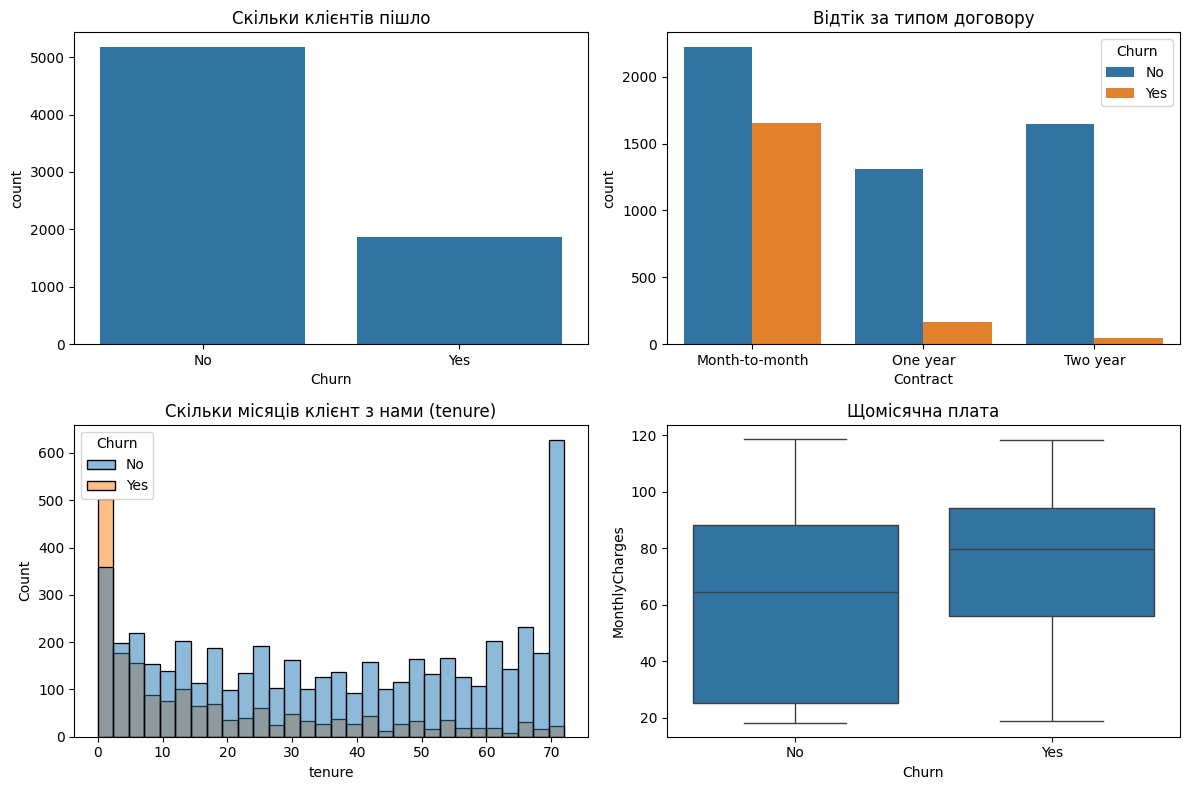

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Скільки клієнтів пішло")

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Відтік за типом договору")

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Скільки місяців клієнт з нами (tenure)")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 1])
axes[1, 1].set_title("Щомісячна плата")

plt.tight_layout()
plt.show()

**Короткі спостереження:** у наборі 7043 клієнти, явних пропусків немає, але в TotalCharges є 11 порожніх рядків (це нові клієнти, у них tenure = 0). Пішло 26.5% клієнтів, тобто класи нерівні: тих, хто залишився, приблизно втричі більше. Найчастіше йдуть клієнти з помісячним договором (42.7%), а з договором на 2 роки лише 2.8%. Ще частіше йдуть клієнти з оптоволоконним інтернетом (41.9%) і ті, хто з компанією зовсім недавно (малий tenure).

## 3. Підготовка даних

In [4]:
data = df.drop(columns=["customerID"]).copy()   # ідентифікатор не потрібен

# TotalCharges читається як текст, переводимо в число
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
# 11 порожніх значень це нові клієнти (tenure = 0), ставимо 0
data["TotalCharges"] = data["TotalCharges"].fillna(0)

# ціль: 1 якщо клієнт пішов, 0 якщо залишився
data["Churn"] = (data["Churn"] == "Yes").astype(int)

X = data.drop(columns="Churn")
y = data["Churn"]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
print("Числові ознаки:", num_cols)
print("Категоріальних ознак:", len(cat_cols))

# train 80%, test 20% (зберігаємо однакову частку тих, хто пішов)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Частка відтоку в train:", round(y_train.mean(), 3), "| у test:", round(y_test.mean(), 3))

# числа масштабуємо, категорії кодуємо в 0/1 (one-hot)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

Числові ознаки: ['tenure', 'MonthlyCharges', 'TotalCharges']
Категоріальних ознак: 16
Train: (5634, 19) | Test: (1409, 19)
Частка відтоку в train: 0.265 | у test: 0.265


## 4. Моделі

Беремо три моделі: логістична регресія (проста), Random Forest і Gradient Boosting (дерева). Підготовка даних і модель об'єднані в один Pipeline. Для логістичної регресії та Random Forest ставимо `class_weight="balanced"`, бо клієнтів, які пішли, помітно менше.

In [5]:
def make_pipe(model):
    return Pipeline([("prep", preprocessor), ("model", model)])


models = {
    "Логістична регресія": make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)),
    "Gradient Boosting": make_pipe(GradientBoostingClassifier(random_state=42)),
}


def evaluate(pipe):
    # метрики на тестовій вибірці
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }


rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    rows.append({"Модель": name, **evaluate(pipe)})

results = pd.DataFrame(rows).set_index("Модель").round(3)
display(results)

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Логістична регресія,0.738,0.504,0.783,0.614,0.842
Random Forest,0.786,0.628,0.473,0.540,0.821
Gradient Boosting,0.803,0.666,0.516,0.581,0.843


## 5. Порівняння моделей

Для відтоку важливо знайти тих, хто піде, тому дивимось не лише на accuracy, а й на **recall** (скільки тих, хто пішов, ми знайшли), **F1** і **ROC-AUC**.

**Що видно з таблиці:** логістична регресія має найкращий recall (0.78) і F1 (0.61), але найменшу accuracy (0.74), бо частіше каже, що клієнт піде, ніж це є насправді. Gradient Boosting має найвищу accuracy (0.80), але знаходить лише половину тих, хто пішов (recall 0.52). Random Forest із параметрами за замовчуванням найслабший за F1 (0.54). За ROC-AUC моделі майже однакові (близько 0.82-0.84).

## 6. Підбір параметрів

Підбираємо параметри кожної моделі через GridSearchCV (3 частини, оцінка за F1) тільки на навчальних даних. Найкращу модель обираємо за результатом кросвалідації, а тест використовуємо вже наприкінці.

In [6]:
grids = {
    "Логістична регресія": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {
        "model__n_estimators": [100, 300],
        "model__max_depth": [5, 10, None],
        "model__min_samples_leaf": [1, 5],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
    },
}

tuned = {}
cv_scores = {}
for name in models:
    gs = GridSearchCV(models[name], grids[name], scoring="f1", cv=3, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    cv_scores[name] = gs.best_score_
    print(name)
    print("  найкращі параметри:", gs.best_params_)
    print("  F1 на кросвалідації:", round(gs.best_score_, 3))

Логістична регресія
  найкращі параметри: {'model__C': 0.1}
  F1 на кросвалідації: 0.634
Random Forest
  найкращі параметри: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
  F1 на кросвалідації: 0.637
Gradient Boosting
  найкращі параметри: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
  F1 на кросвалідації: 0.586


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Random Forest (підібрана),0.764,0.540,0.754,0.629,0.842
Логістична регресія (підібрана),0.742,0.509,0.786,0.618,0.841
Логістична регресія,0.738,0.504,0.783,0.614,0.842
Gradient Boosting,0.803,0.666,0.516,0.581,0.843
Gradient Boosting (підібрана),0.802,0.664,0.513,0.579,0.844
Random Forest,0.786,0.628,0.473,0.540,0.821


Найкраща модель: Random Forest


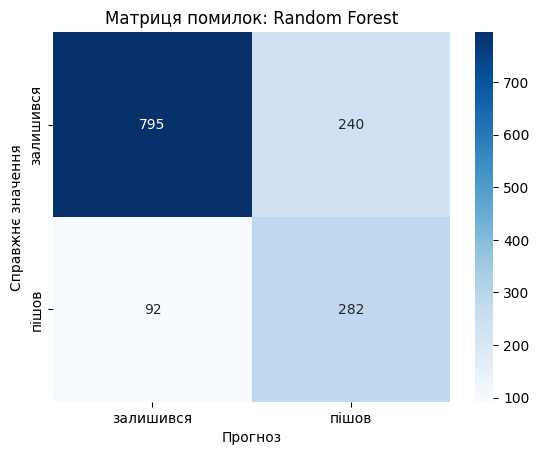

In [7]:
# метрики моделей з підібраними параметрами на тесті
rows = []
for name, pipe in tuned.items():
    rows.append({"Модель": name + " (підібрана)", **evaluate(pipe)})

results_tuned = pd.DataFrame(rows).set_index("Модель").round(3)
all_results = pd.concat([results, results_tuned]).sort_values("F1", ascending=False)
display(all_results)

# найкраща модель за F1 на кросвалідації
best_name = max(cv_scores, key=cv_scores.get)
best_model = tuned[best_name]
print("Найкраща модель:", best_name)

# матриця помилок найкращої моделі
cm = confusion_matrix(y_test, best_model.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["залишився", "пішов"], yticklabels=["залишився", "пішов"])
plt.xlabel("Прогноз")
plt.ylabel("Справжнє значення")
plt.title("Матриця помилок: " + best_name)
plt.show()

**Результат підбору параметрів:** найбільше покращився Random Forest: F1 зріс з 0.54 до 0.63, а recall з 0.47 до 0.75. Логістична регресія і Gradient Boosting майже не змінились. За F1 на кросвалідації найкращим став Random Forest (0.64), але логістична регресія дуже близька (0.63), а ROC-AUC у всіх моделей приблизно 0.84. Тому як найкращу беремо Random Forest з підібраними параметрами: на тесті accuracy 0.76, recall 0.75, F1 0.63.

## 7. Прогноз для клієнта

Функція `predict_client` приймає дані одного клієнта і показує, чи піде він. Значення в словниках можна змінювати й запускати клітинку ще раз.

In [8]:
def predict_client(client):
    row = pd.DataFrame([client])
    proba = best_model.predict_proba(row)[0, 1]
    answer = "ПІДЕ" if proba >= 0.5 else "ЗАЛИШИТЬСЯ"
    print(f"Ймовірність відтоку: {proba:.2f}. Прогноз: клієнт {answer}")


# клієнт 1: новий, договір помісячний, дорогий інтернет, оплата електронним чеком
client_1 = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 80.0, "TotalCharges": 160.0,
}

# клієнт 2: давній, договір на 2 роки, з підтримкою
client_2 = {
    "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
    "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
    "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
    "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No", "StreamingMovies": "No",
    "Contract": "Two year", "PaperlessBilling": "No", "PaymentMethod": "Credit card (automatic)",
    "MonthlyCharges": 65.0, "TotalCharges": 3900.0,
}

print("Клієнт 1:")
predict_client(client_1)
print("Клієнт 2:")
predict_client(client_2)

Клієнт 1:
Ймовірність відтоку: 0.86. Прогноз: клієнт ПІДЕ
Клієнт 2:
Ймовірність відтоку: 0.05. Прогноз: клієнт ЗАЛИШИТЬСЯ


## 8. Висновки

У даних про 7043 клієнтів пішло близько 26.5%, тому класи нерівні і для оцінки важливі recall та F1, а не лише accuracy. Найбільше на відтік впливають тип договору і час, який клієнт з нами: з помісячним договором іде 42.7% клієнтів, а з договором на 2 роки лише 2.8%. Ми порівняли логістичну регресію, Random Forest і Gradient Boosting, за ROC-AUC вони майже однакові (близько 0.84), але відрізняються за recall. Найкращою обрали Random Forest з підібраними параметрами (accuracy 0.76, recall 0.75, F1 0.63), хоча логістична регресія майже така сама за якістю і простіша. Модель можна використовувати для прогнозу окремого клієнта (у прикладі клієнт 1 піде з імовірністю близько 0.86, а клієнт 2 залишиться), але вона помиляється приблизно в кожному четвертому випадку, тому її краще використовувати як підказку для відділу роботи з клієнтами, а не як остаточне рішення.